In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
file_names = ["time_domain_signal1.csv","time_domain_signal2.csv","time_domain_signal3.csv","time_domain_signal4.csv","time_domain_signal5.csv",]
signals = []
for name in file_names:
    data = np.loadtxt(name, delimiter=",")
    signals.append(data)
    print(name, "-> number of samples =", len(data))

time_domain_signal1.csv -> number of samples = 501
time_domain_signal2.csv -> number of samples = 501
time_domain_signal3.csv -> number of samples = 501
time_domain_signal4.csv -> number of samples = 1002
time_domain_signal5.csv -> number of samples = 1002


In [3]:
fs = 501
print("sampling rate used:", fs, "Hz")

sampling rate used: 501 Hz


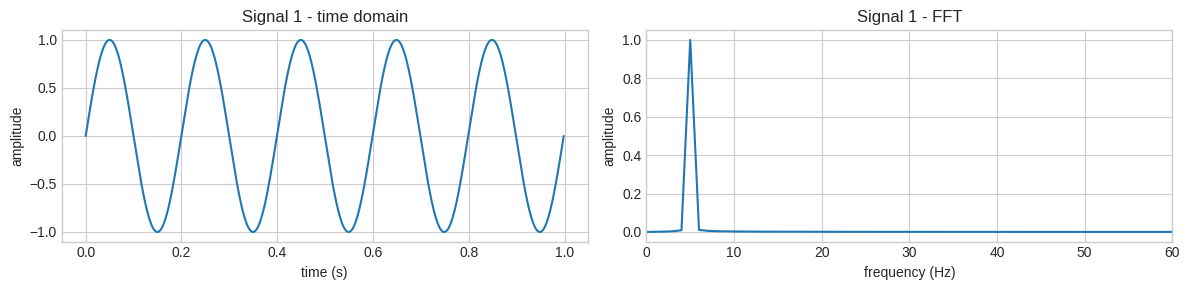

Signal 1: strongest frequency = 5.00 Hz


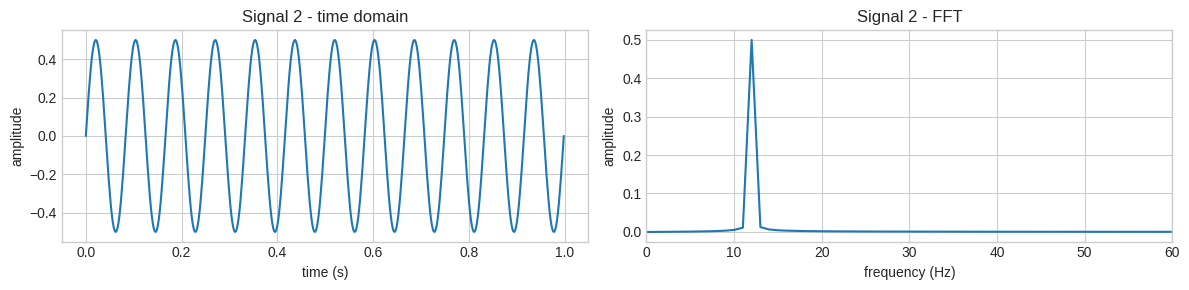

Signal 2: strongest frequency = 12.00 Hz


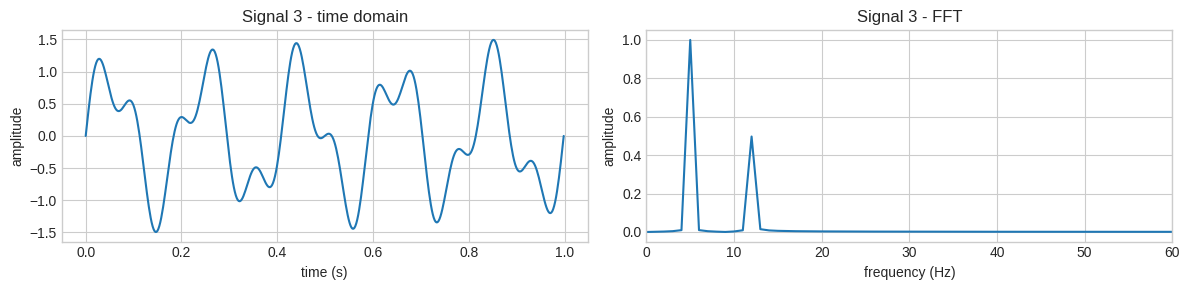

Signal 3: strongest frequency = 5.00 Hz


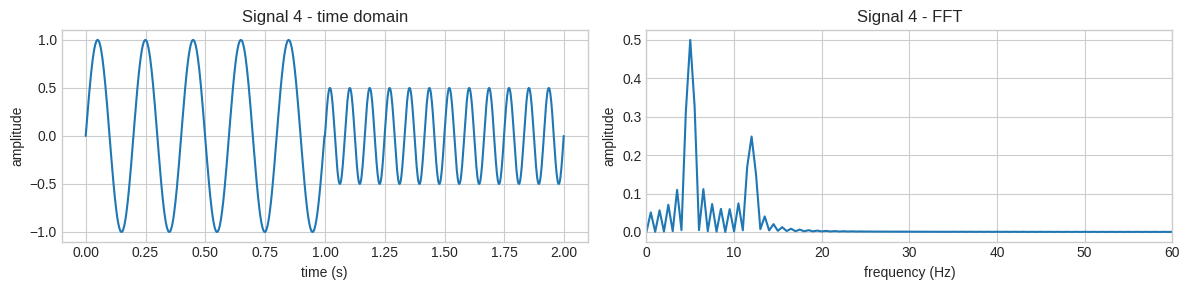

Signal 4: strongest frequency = 5.00 Hz


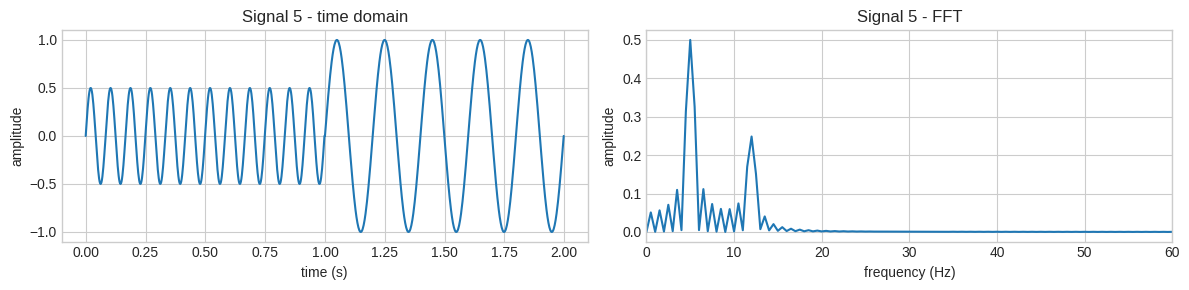

Signal 5: strongest frequency = 5.00 Hz


In [4]:
# FFT part
for i in range(5):
    x = signals[i]
    n = len(x)
    t = np.arange(n) / fs
    
    # doing the FFT
    X = np.fft.rfft(x)
    freq = np.fft.rfftfreq(n, d=1/fs)
    mag = np.abs(X) / n * 2   # scaling so the height matches the real amplitude

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3))
    ax1.plot(t, x)
    ax1.set_title(f"Signal {i+1} - time domain")
    ax1.set_xlabel("time (s)")
    ax1.set_ylabel("amplitude")
    ax2.plot(freq, mag)
    ax2.set_xlim(0, 60)  
    ax2.set_title(f"Signal {i+1} - FFT")
    ax2.set_xlabel("frequency (Hz)")
    ax2.set_ylabel("amplitude")
    plt.tight_layout()
    plt.show()

    peak_index = np.argmax(mag[1:]) + 1   
    print(f"Signal {i+1}: strongest frequency = {freq[peak_index]:.2f} Hz")